<a href="https://colab.research.google.com/github/nathannguyen13/A04-clustering/blob/main/notebook_(4).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Nathan Nguyen

**Date:** 10/13/2026

In [27]:
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

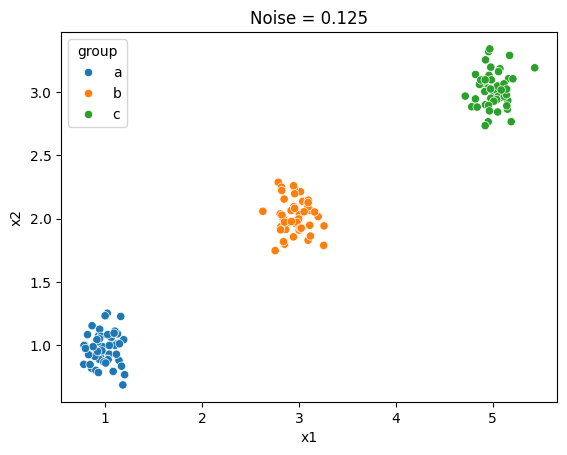

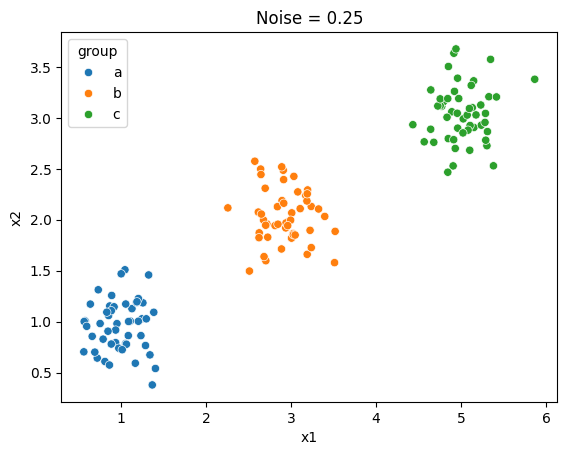

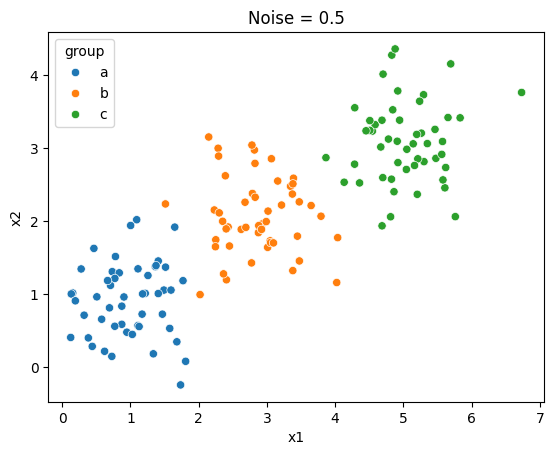

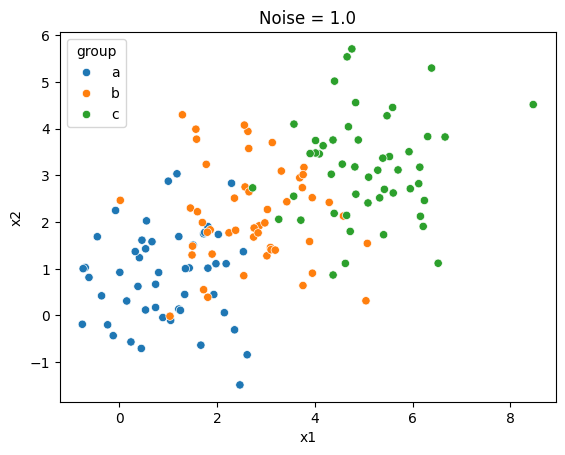

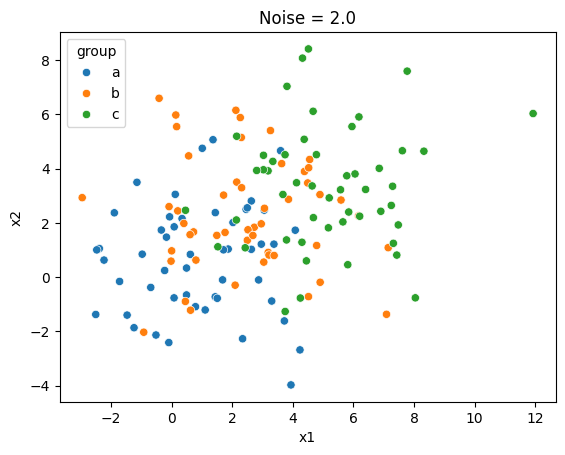

In [28]:
#2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

datasets = [df0_125, df0_25, df0_5, df1_0, df2_0]
noises = [0.125, 0.25, 0.5, 1.0, 2.0]

for df, noise in zip(datasets, noises):
    sns.scatterplot(data=df, x='x1', y='x2', hue='group')
    plt.title(f'Noise = {noise}')
    plt.show()

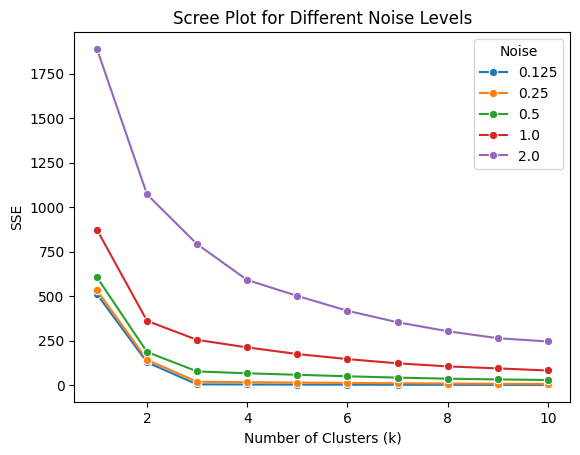

In [29]:
#3
from sklearn.cluster import KMeans

for df, noise in zip(datasets, noises):
    X = df[['x1', 'x2']]
    ks = np.arange(1, 11)

    SSE = [
        KMeans(n_clusters=k, n_init=10, random_state=0)
        .fit(X).inertia_
        for k in ks
    ]

    sns.lineplot(x=ks, y=SSE, marker='o', label=str(noise))

plt.title('Scree Plot for Different Noise Levels')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('SSE')
plt.legend(title='Noise')
plt.show()

#4
The elbow is where adding more clusters stops making a big difference in SSE. In this simulation, the elbow is around k = 3 for lower noise levels. As noise increases, the elbow becomes less clear, making it harder to choose k.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts?
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

In [30]:
#1
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

df = pd.read_csv('A04-clustering/data/SIPRI Military Expenditure Database.csv')

df = df[df['Year'] == 2020].dropna()
df = df.drop(columns=['index', 'Year'])

print(df.shape)
df.head()

(148, 5)


,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
32,Afghanistan,279.576955,0.013589,0.049728,7.181899
66,Albania,187.433234,0.012583,0.037952,65.126211
100,Algeria,9708.277440,0.066600,0.173924,221.392384
134,Angola,993.594405,0.014442,0.074624,30.231680
168,Argentina,2830.929705,0.007269,0.017268,62.636731


After filtering for 2020 and removing missing values, there are 148 countries. No further major cleaning is needed, but the numeric variables need to be normalized before clustering.

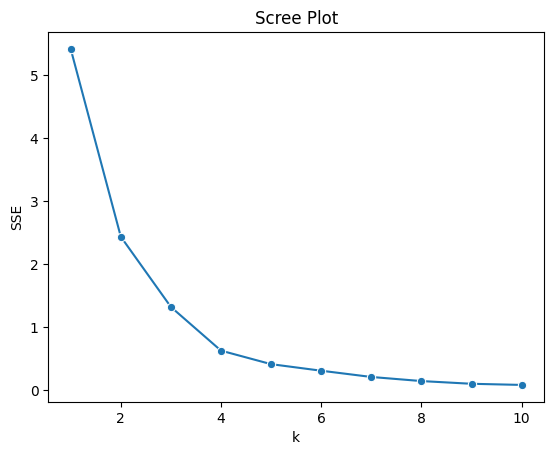

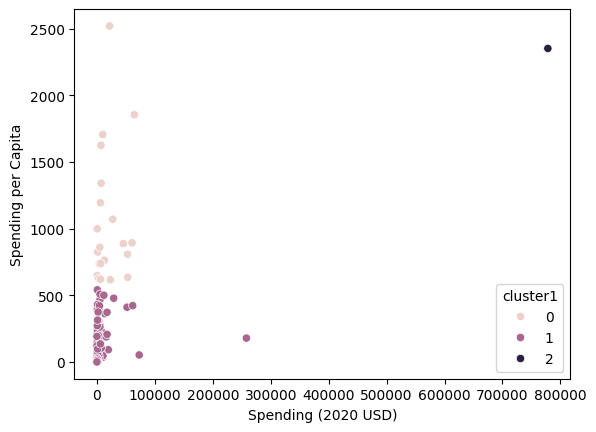

,Country,cluster1
5540,United States of America,2


In [31]:
#2

#Scree plot
cols = ['Spending (2020 USD)', 'Spending per Capita']

X = df[cols]
X = (X - X.min()) / (X.max() - X.min())

ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]

sns.lineplot(x=ks, y=SSE, marker='o')
plt.title('Scree Plot')
plt.xlabel('k')
plt.ylabel('SSE')
plt.show()

#Cluster and scatterplot
model = KMeans(n_clusters=3, n_init=10, random_state=0)
df['cluster1'] = model.fit_predict(X)

sns.scatterplot(
    data=df,
    x=cols[0],
    y=cols[1],
    hue='cluster1'
)
plt.show()

df.groupby('cluster1')[cols].describe()

df[df['Country'].str.contains('United States', case=False)][
    ['Country', 'cluster1']
]

Most countries are grouped into a cluster with relatively low military spending. The United States stands out because it spends much more than other countries and forms its own cluster. Countries with higher spending per capita also tend to be separated from the majority.

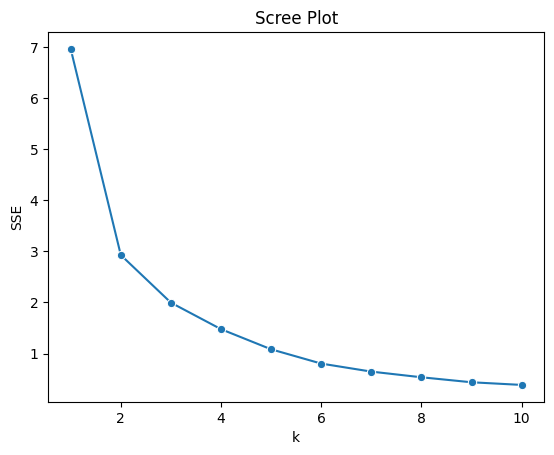

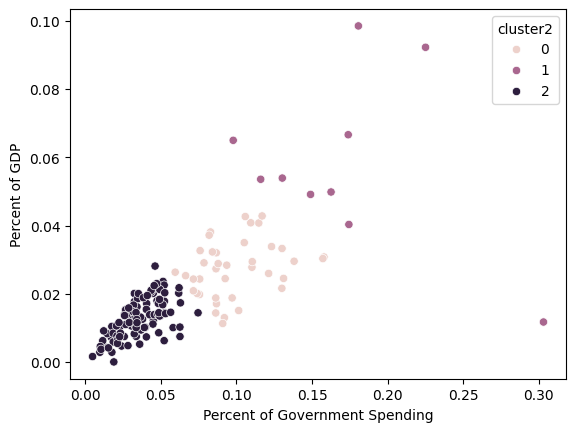

Percent of Government Spending                                \
                                  count      mean       std       min   
cluster2                                                                
0                                  39.0  0.098683  0.024125  0.059520   
1                                  10.0  0.171289  0.058725  0.097882   
2                                  99.0  0.035777  0.014549  0.004896   

                                                 Percent of GDP            \
               25%       50%       75%       max          count      mean   
cluster2                                                                    
0         0.082430  0.092044  0.112633  0.157918           39.0  0.027412   
1         0.135010  0.168248  0.179081  0.303027           10.0  0.058071   
2         0.025921  0.034261  0.047402  0.074624           99.0  0.012664   

                                                                      
               std       min       25%       50%       75%       max  
cluster2                                                              
0         0.008191  0.011317  0.021254  0.027781  0.032461  0.042810  
1         0.024867  0.011742  0.049297  0.053729  0.066190  0.098470  
2         0.005681  0.000054  0.008393  0.013191  0.016752  0.028132

In [32]:
#3
cols2 = ['Percent of Government Spending', 'Percent of GDP']

X2 = df[cols2]
X2 = (X2 - X2.min()) / (X2.max() - X2.min())

SSE = [
    KMeans(n_clusters=k, n_init=10, random_state=0)
    .fit(X2).inertia_
    for k in ks
]

sns.lineplot(x=ks, y=SSE, marker='o')
plt.title('Scree Plot')
plt.xlabel('k')
plt.ylabel('SSE')
plt.show()

model2 = KMeans(n_clusters=3, n_init=10, random_state=0)
df['cluster2'] = model2.fit_predict(X2)

sns.scatterplot(
    data=df,
    x=cols2[0],
    y=cols2[1],
    hue='cluster2'
)
plt.show()

df.groupby('cluster2')[cols2].describe()

Unlike the previous part, these clusters are based on how much of a country's resources go toward the military rather than the total amount spent. Countries that spend a larger percentage of their GDP or government budget on the military are grouped together.

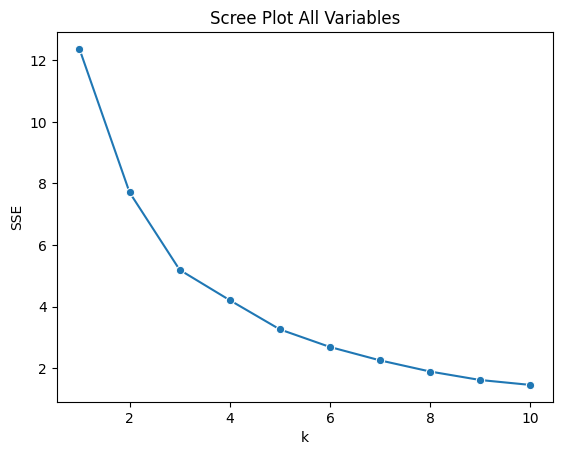

Spending (2020 USD)                                             \
                       count           mean            std          min   
cluster3                                                                  
0                      111.0    7086.472777   26479.379918     8.622460   
1                       31.0    8786.086602   17901.909108   162.373364   
2                        6.0  147964.582042  309635.189564  6095.708713   

                                                                  \
                  25%           50%           75%            max   
cluster3                                                           
0          130.010211    567.650747   3910.107493  257973.429834   
1          467.787851   1404.787234   7739.166193   72937.064048   
2         7700.424616  15897.570598  53872.942442  778397.200000   

         Spending per Capita               ... Percent of Government Spending  \
                       count         mean  ...                            75%   
cluster3                                   ...                                  
0                      111.0   196.926833  ...                       0.050505   
1                       31.0   212.689100  ...                       0.134663   
2                        6.0  1875.150751  ...                       0.164503   

                   Percent of GDP                                          \
               max          count      mean       std       min       25%   
cluster3                                                                    
0         0.092044          111.0  0.013419  0.005996  0.000054  0.008873   
1         0.303027           31.0  0.033492  0.011449  0.011742  0.027560   
2         0.225050            6.0  0.062634  0.028275  0.029429  0.041272   

                                        
               50%       75%       max  
cluster3                                
0         0.013589  0.017769  0.028132  
1         0.032024  0.040531  0.066600  
2         0.059257  0.085398  0.098470  

[3 rows x 32 columns]

In [33]:
#4
cols3 = [
    'Spending (2020 USD)',
    'Spending per Capita',
    'Percent of Government Spending',
    'Percent of GDP'
]

X3 = df[cols3]
X3 = (X3 - X3.min()) / (X3.max() - X3.min())

SSE = [
    KMeans(n_clusters=k, n_init=10, random_state=0)
    .fit(X3).inertia_
    for k in ks
]

sns.lineplot(x=ks, y=SSE, marker='o')
plt.title('Scree Plot All Variables')
plt.xlabel('k')
plt.ylabel('SSE')
plt.show()

model3 = KMeans(n_clusters=3, n_init=10, random_state=0)
df['cluster3'] = model3.fit_predict(X3)

df.groupby('cluster3')[cols3].describe()

Using all four variables gives a broader comparison of military spending. Instead of focusing only on total spending or percentages, the clusters consider both. This helps identify countries with similar spending patterns.

#5
Yes, k-means helped identify differences in military spending between countries. Some countries spend much more overall, while others dedicate a larger percentage of their resources to the military. It was useful for grouping countries with similar spending patterns.

---

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** ebf850c9812aa2c399ea8f153ff71e9d5d1edc55
- **AI tool and model used:** ChatGPT 5.6

### *Prompts used

1. Now looking at my answers for section q1, is there any way you would optimize it so that it accurately carries out each question

2. now looking at my answers for section q2, is there any way you would optimize it so that it accurately carries out each question

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. Yes. Looking at your Q1 code and answers, I would make a few small improvements to ensure you fully address every part of the question without overcomplicating it.
1. Scatterplots
Your current code works, but I would add plt.figure() and use the same axis limits for every graph. This makes it easier to compare how the clusters spread out as noise increases.
datasets = [df0_125, df0_25, df0_5, df1_0, df2_0]noises = [0.125, 0.25, 0.5, 1.0, 2.0]for df, noise in zip(datasets, noises):    plt.figure(figsize=(6, 4))    sns.scatterplot(data=df, x='x1', y='x2', hue='group')    plt.title(f'Noise = {noise}')    plt.xlim(-5, 12)    plt.ylim(-5, 12)    plt.show()



Your written answer can stay the same:
As noise increases, the clusters become less distinct. At lower noise levels, the groups are clearly separated, but at higher noise levels, the points become more spread out and overlap.

2. Scree plots
Your current scree plot combines all five noise levels into one graph, which is exactly what the assignment allows.
However, I would recommend creating separate plots as well because the high-noise curves make the lower-noise curves difficult to see.
fig, axes = plt.subplots(1, 5, figsize=(18, 4))for i, (df, noise) in enumerate(zip(datasets, noises)):    X = df[['x1', 'x2']]    ks = np.arange(1, 11)    SSE = [        KMeans(n_clusters=k, n_init=10, random_state=0)        .fit(X).inertia_        for k in ks    ]    sns.lineplot(x=ks, y=SSE, marker='o', ax=axes[i])    axes[i].set_title(f'Noise = {noise}')    axes[i].set_xlabel('k')    axes[i].set_ylabel('SSE')plt.tight_layout()plt.show()



This lets you see each elbow more clearly.
Improved written answer:
At lower noise levels, the scree plots have a clear elbow around k = 3. As noise increases, the elbow becomes less noticeable, making it harder to determine the best k. The SSE values also increase as noise increases.

3. Explain the elbow
Your previous answer was already good. I would only make a small adjustment to connect it more directly to your simulation.
Improved answer:
The elbow is where adding more clusters stops significantly reducing SSE. In this simulation, k = 3 is a good choice at lower noise levels because there are three groups. As noise increases, the elbow becomes less clear, making it harder to choose k.


My recommendation
Your Q1 is already close to complete. The main improvements are:
- Scatterplots: Keep the axes consistent so the noise levels are easier to compare.
- Scree plots: Show separate plots to make the elbows easier to see.
- Written answers: Mention that higher noise increases SSE and makes choosing k more difficult.


2. Yes. Your Q2 is mostly correct, but I would make a few improvements to ensure you fully answer every part of the assignment while keeping the code simple and consistent with your professor's slides.
The biggest improvements are making sure you select k based on the scree plots, identify the United States, and compare the clusters between Parts 2, 3, and 4.
1. Loading and cleaning the data
Your existing code is good. I would just add a check to confirm the numeric columns are actually numeric.
df = pd.read_csv('A04-clustering/data/SIPRI Military Expenditure Database.csv')df = df[df['Year'] == 2020].dropna()df = df.drop(columns=['index', 'Year'])print(df.shape)print(df.dtypes)df.head()



Improved answer:
After filtering for 2020 and removing missing values, there are 148 countries. No additional cleaning is needed because the spending variables are numeric. However, normalization is necessary before clustering because the variables have different scales.

2. Spending and Spending per Capita
Your normalization and scree plot code are already correct.
The main improvement is to check the scree plot before choosing k, rather than automatically assuming k = 3.
You can keep your current code, but add the following after clustering:
print(df.groupby('cluster1')[cols].describe())print(df.groupby('cluster1').size())print(df[df['Country'].str.contains('United States', case=False)][    ['Country', 'cluster1']])



This provides the summary statistics, the number of countries in each cluster, and the United States' cluster membership.
Improved answer:
The scree plot suggests that k = 3 is a reasonable choice. Most countries belong to a cluster with relatively low military spending. The United States forms its own cluster because its total spending is much higher than other countries. Another cluster contains countries with higher spending per capita.

3. Percent of Government Spending and Percent of GDP
Your code is correct, but I would add a cluster size table and check where the United States is located.
Add this after your Part 3 code:
print(df.groupby('cluster2')[cols2].describe())print(df.groupby('cluster2').size())print(df[df['Country'].str.contains('United States', case=False)][    ['Country', 'cluster2']])



Improved answer:
Unlike Part 2, these clusters focus on how much of a country's resources are spent on the military rather than the total amount. Countries like Saudi Arabia and Israel are grouped together because they dedicate a higher percentage of their resources to military spending. The United States no longer forms its own cluster.

4. All four numeric variables
Your current code correctly normalizes all four variables and runs k-means.
However, the assignment asks you to compare these results to the previous two parts. I would add a cluster comparison table.
print(df.groupby('cluster3')[cols3].describe())print(df.groupby('cluster3').size())# Compare cluster membershipprint(pd.crosstab(df['cluster1'], df['cluster3']))print(pd.crosstab(df['cluster2'], df['cluster3']))



These tables show how countries are grouped differently when all four variables are considered.
You can also add a scatterplot for Part 4, even though the assignment doesn't explicitly require one:
sns.scatterplot(    data=df,    x='Spending (2020 USD)',    y='Spending per Capita',    hue='cluster3')plt.title('Clustering Using All Four Variables')plt.show()



Improved answer:
Using all four variables creates clusters based on both total military spending and the percentage of resources spent on the military. Compared to Parts 2 and 3, this gives a broader comparison of countries. The United States is no longer isolated in its own cluster because other spending factors are also considered.

5. Did k-means find useful patterns?
Your original answer is good, but I would connect it more directly to the results.
Improved answer:
Yes, k-means helped identify patterns in military spending across countries. Some countries spend much more overall, while others spend a larger percentage of their resources on the military. However, countries with unusually high spending can influence the clusters.


Final recommendations
I checked the uploaded CSV and confirmed that the data has 148 complete observations for 2020, with all four spending variables already numeric.
Here are the cluster sizes using your existing code with k = 3:
Part	Cluster 0	Cluster 1	Cluster 2
2	21	126	1
3	39	10	99
4	111	31	6
The most important changes I recommend are:
1. Part 1: Check the data types to verify no additional cleaning is necessary.
2. Part 2: Explain the scree plot, identify the United States, and show the cluster sizes.
3. Part 3: Compare the percentage-based clusters with the spending-based clusters.
4. Part 4: Add comparison tables to demonstrate how cluster membership changes.
5. Part 5: Explain what k-means revealed and acknowledge its limitations.

### *Evaluation of AI suggestions




```
# This is formatted as code
```

| Change | Decision | Reason and verification |
|---|---|---|
| 1 | **Accept** / modify / reject | The change made my charts look a lot neater. For example, my new solution for Q1-2 allows me to see all of the scree plots at once |
| 2 | Accept / modify / **reject** | The changes the AI suggested for 3 and 4 seemed ok but my original code already covers everything well so no need for changes |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

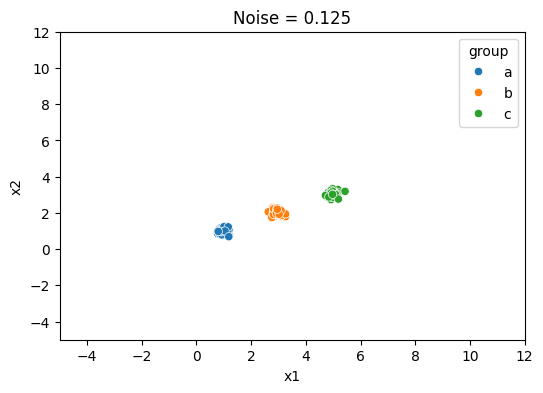

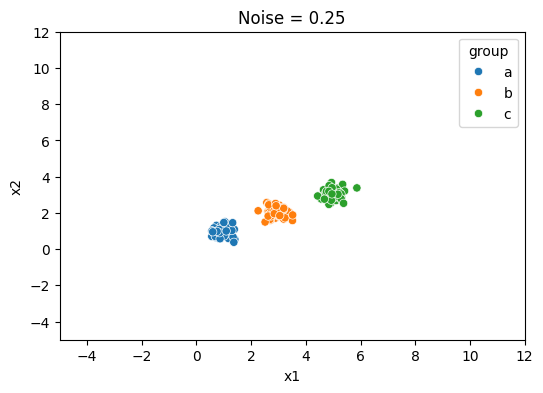

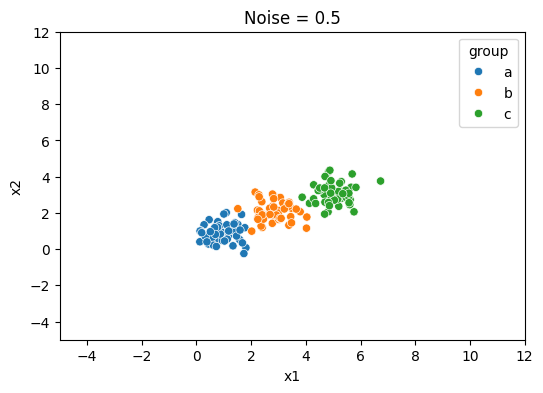

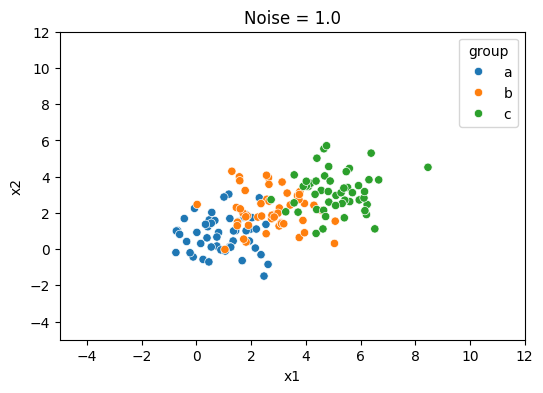

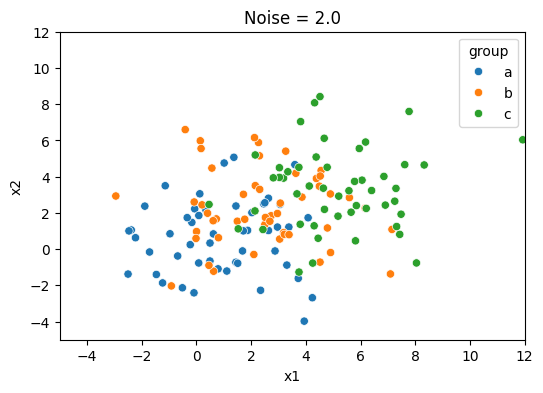

In [34]:
# Your Phase 2 solution to the problem goes here.

#Q1-1
datasets = [df0_125, df0_25, df0_5, df1_0, df2_0]
noises = [0.125, 0.25, 0.5, 1.0, 2.0]

for df, noise in zip(datasets, noises):
    plt.figure(figsize=(6, 4))
    sns.scatterplot(data=df, x='x1', y='x2', hue='group')

    plt.title(f'Noise = {noise}')
    plt.xlim(-5, 12)
    plt.ylim(-5, 12)
    plt.show()

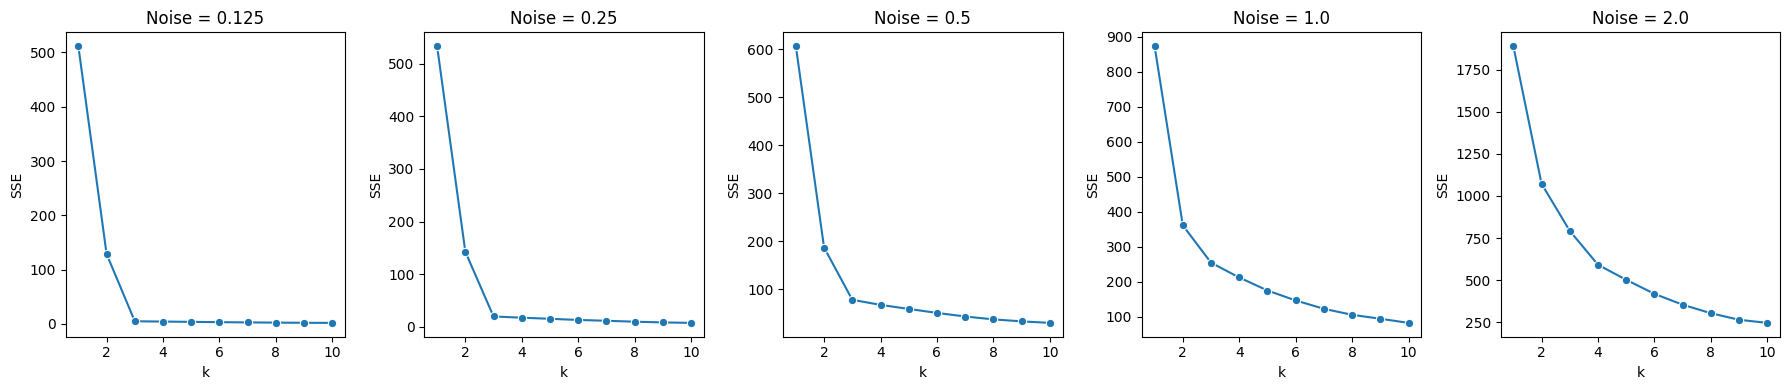

In [35]:
#Q1-2
fig, axes = plt.subplots(1, 5, figsize=(18, 4))

for i, (df, noise) in enumerate(zip(datasets, noises)):
    X = df[['x1', 'x2']]
    ks = np.arange(1, 11)

    SSE = [
        KMeans(n_clusters=k, n_init=10, random_state=0)
        .fit(X).inertia_
        for k in ks
    ]

    sns.lineplot(x=ks, y=SSE, marker='o', ax=axes[i])
    axes[i].set_title(f'Noise = {noise}')
    axes[i].set_xlabel('k')
    axes[i].set_ylabel('SSE')

plt.tight_layout()
plt.show()

At lower noise levels, the scree plots have a clear elbow around k = 3. As noise increases, the elbow becomes less noticeable, making it harder to determine the best k. The SSE values also increase as noise increases.

### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]

Overall, my original code was already fairly close to what the assignment required, so I did not need to make many major changes. For Q1, I improved the scatterplots by keeping the axes consistent, which made it easier to compare how the clusters changed as noise increased. I also considered using separate scree plots to make the elbows easier to identify. For Q2, I reviewed my code to make sure I was correctly normalizing the variables, creating scree plots, and using k-means clustering, but I didn't make any final changes. One issue I encountered was a KeyError when trying to select columns from my DataFrame. This was likely caused by the DataFrame being overwritten or the columns not matching what I expected. I was able to figure this out by asking Chat to troubleshoot. To verify my work, I checked that the code ran without errors and reviewed the scatterplots, scree plots, and summary statistics to see whether the results made sense. I also compared the clustering results across the different variables. My main remaining concern is choosing the optimal number of clusters. Some scree plots have a clear elbow, while others are harder to interpret. Overall, I think my final code was able to meet the assignment requirements.